In [26]:
using Pkg
Pkg.activate("/Users/alia/Desktop/envs/ants")
using Plots
using DifferentialEquations
using LaTeXStrings
using NLsolve
using IntervalArithmetic, IntervalArithmetic.Symbols, IntervalRootFinding
using LinearAlgebra
using Plots.PlotMeasures
xgfs_normal12 = [(235, 172, 35), (184, 0, 88), (0, 140, 249), (0, 110, 0), (0, 187, 173), (209, 99, 230), (178, 69, 2), (255, 146, 135), (89, 84, 214), (0, 198, 248), (135, 133, 0), (0, 167, 108), (189, 189, 189)]
pal = [RGB(r/255, g/255, b/255) for (r,g,b) in xgfs_normal12]

  Activating project at `~/Desktop/envs/ants`


In [27]:
function model_4d!(dx,x,p,t)
    (alphaC,alphaB,alphaT,beta,omegaC,omegaB,k,n,gamma)=p
    S,C,B,T = x
    H = 1 - S - B - C - T
    dx[1] = (-(alphaC+alphaB+alphaT)*S) + gamma*H
    dx[2] = alphaC*S - omegaC*C/(1+ (C/k)^n)
    dx[3] = alphaB*S - omegaB*B/(1+ (C/k)^n)
    dx[4] = alphaT*S - beta*T
    return nothing
end

model_4d! (generic function with 1 method)

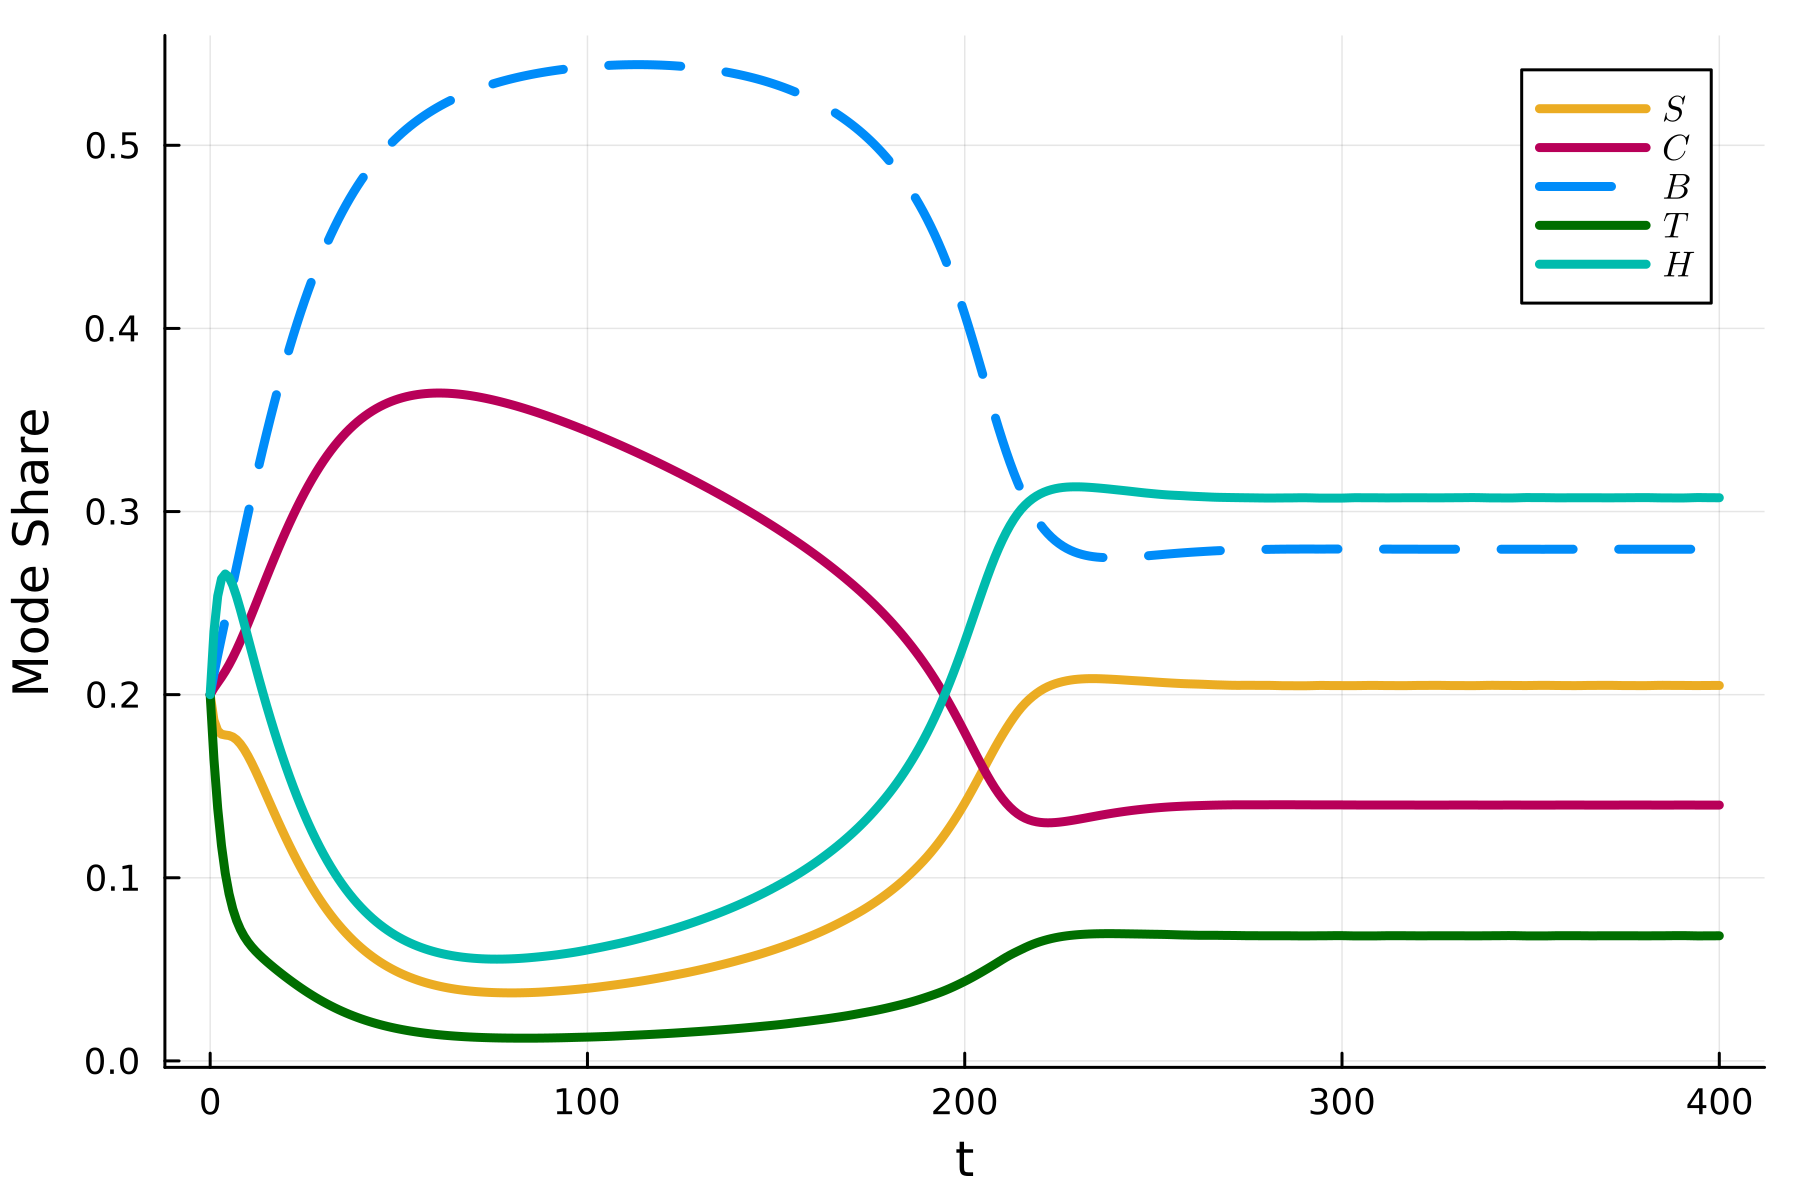

In [135]:
par = (alphaC = 0.4, alphaB = 0.3, alphaT = 0.8,beta = 0.07, omegaC = 1.2, omegaB = 0.012, k = 0.005, n = 3,gamma = 7.0) # gives oscillation
par = (alphaC=0.1,alphaB=0.1,alphaT=0.1,beta=0.3,omegaC=0.2,omegaB=0.1,k=0.18,n=4,gamma = 0.2)


u0 = [0.2,0.2,0.2,0.2]
#u0 = [0.00216054 0.01280848 0.95987615 0.02469186]
tspan=(0.0,400.0)

prob_4d = ODEProblem(model_4d!,u0,tspan,par)
sol4d = DifferentialEquations.solve(prob_4d,saveat = 1.0,Tsit5())
S4,C4,B4,T4 = sol4d[1,:],sol4d[2,:],sol4d[3,:],sol4d[4,:]
H4 = 1 .- S4 .- C4 .- B4 .-T4

p1 = plot(sol4d.t, vec(S4), label = L"S",  lw=3, color = pal[1],xlabel = "t",ylabel = "Mode Share",dpi = 300)
plot!(p1, sol4d.t, vec(C4), label = L"C",   lw=3, color = pal[2])
plot!(p1, sol4d.t, vec(B4), label = L"B",   lw=3, color = pal[3],linestyle = :dash)
plot!(p1, sol4d.t, vec(T4), label = L"T",   lw=3, color = pal[4])
plot!(p1, sol4d.t, vec(H4), label = L"H",   lw=3, color = pal[5])
#println(C4[end])

Any[

┌ Warning: Could not infer the return type of the function (it may be type instable). Got Any
└ @ IntervalRootFinding /Users/alia/.julia/packages/IntervalRootFinding/U9NQG/src/roots.jl:69


0.13970831504953268]


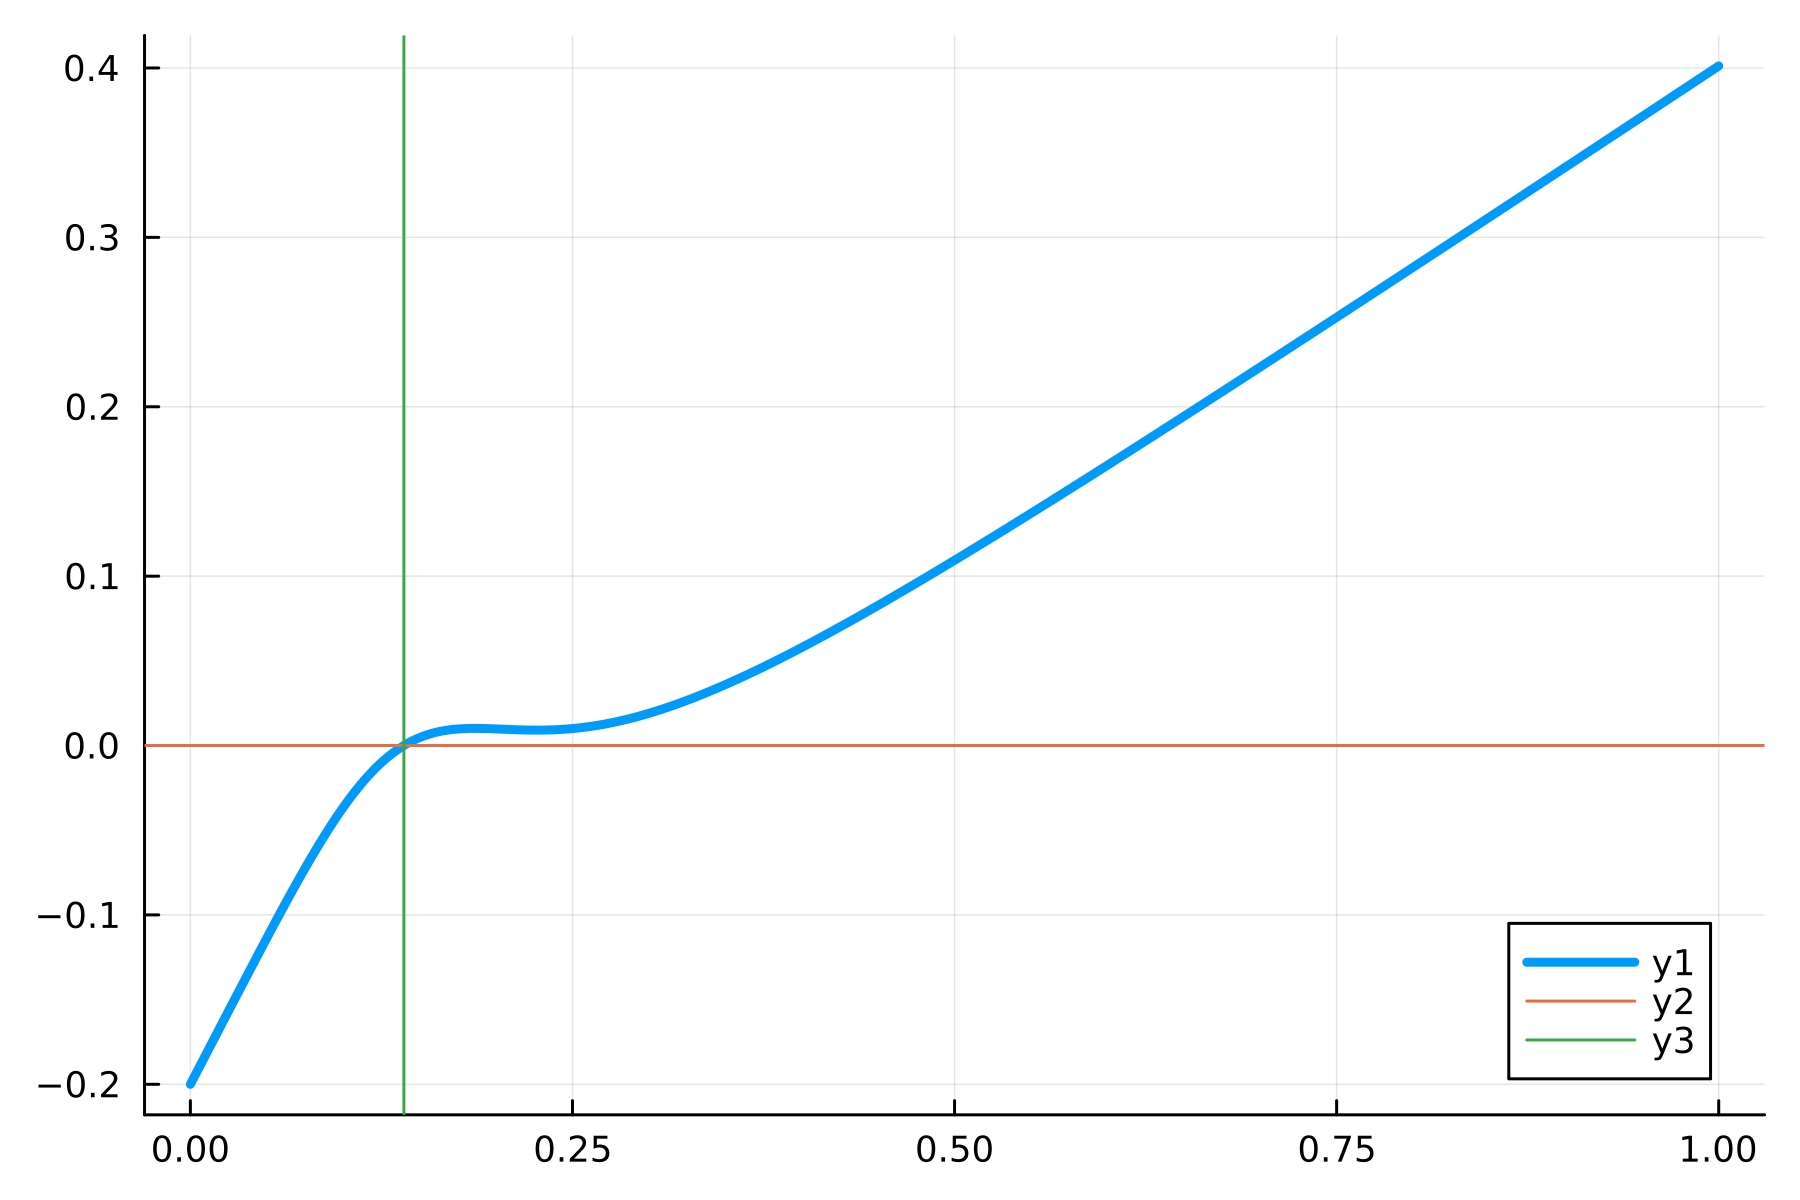

In [136]:
alphaC,alphaB,alphaT,beta,omegaC,omegaB,k,n,gamma = par
A = omegaC/alphaC * (alphaC + alphaB + alphaT + gamma + gamma*alphaT/beta)
D = gamma * (1 + (omegaC*alphaB)/(omegaB*alphaC))

function equilibrium(C)
    return float(A*(C/(1 + (C/k)^n)) - gamma + D*C)
end

C_star =[]
roots_sol = roots(equilibrium,0..1)
for result in roots_sol
    if result.status == :unique
        push!(C_star,0.5 * (sup(result.region) +inf(result.region)))
    end
end

x = range(0.0, 1, length=1000)
y = @. equilibrium(x)
println(C_star)
plot(x,y,dpi = 300, lw= 3)
hline!([0])
vline!([C_star])


In [137]:
B_star = omegaC*alphaB / (omegaB*alphaC) .* C_star
S_star = omegaC .* C_star ./ (alphaC .* (1 .+ (C_star ./ k) .^n))
T_star = alphaT/beta .* S_star

println(S_star,C_star,B_star,T_star)

[0.2050147252416713]Any[0.13970831504953268][0.27941663009906537][0.06833824174722378]


In [138]:
Tclear = beta .* T_star
Bclear = omegaB .* B_star ./ (1 .+ (C_star ./ k) .^n)
Cclear = omegaC .* C_star ./ (1 .+ (C_star ./ k) .^n)

println(Cclear,Bclear,Tclear)
println(Cclear .+ Bclear .+ Tclear)

[0.020501472524167133][0.020501472524167133][0.020501472524167133]
[0.0615044175725014]


In [142]:
function clear_rate(sol,par)
    S,C,B,T = sol[1,end],sol[2,end],sol[3,end],sol[4,end]
    g = 1/ (1 + (C/par.k)^par.n)
    return par.beta * T + (par.omegaB*B + par.omegaC*C)*g
end


clear_rate (generic function with 1 method)

1-element Vector{Float64}:
 0.007936482942332025